# Regressão Linear Múltipla

Regressão Linear Simples pode ser expandida para utilizar mais variáveis preditoras. Temos então a regressão linear múltipla. Tecnicamente, regressão polinomial (como visto anteriormente) já é um caso de regressão linear múltipla.

## Dados

Vamos utilizar o banco de dados `state.x77` disponível em R na forma de matriz com os dados dos 50 estados dos Estados Unidos. As variáveis são:

|Nome original|Nome|Descrição|Tradução (livre)|
|:-|:-|:-|:-|
|`Population`|`populacao`|_population estimate as of July 1, 1975_|população estimada em 01/07/1975|
|`Income`|`renda`|_per capita income (1974)_|renda per capita em 1974|
|`Illiteracy`|`analfabetismo`|_illiteracy (1970, percent of population)_|analfabetismo (porcentagem da população em 1970)|
|`Life Exp`|`expectativa`|_life expectancy in years (1969–71)_|expectativa de vida em anos (1961-1971)|
|`Murder`|`assassinato`|_murder and non-negligent manslaughter rate per 100,000 population (1976)_|taxa de homicídios e homicídios culposos não negligentes por 100.000 habitantes (1976)|
|`HS Grad`|`ens_medio`|_percent high-school graduates (1970)_|porcentagem de concluintes do ensino médio (1970)|
|`Frost`|`congelamento`|_mean number of days with minimum temperature below freezing (1931–1960) in capital or large city_|número médio de dias com temperaturas mínimas abaixo do ponto de congelamento (1931-1960) na capital ou em grandes cidades|
: {tbl-colwidths="[13,17,35,35]"}

Foram incorporadas as variáveis `state.region` como `regiao` e `state.name`  como `estado`. O conjunto de dados foi salvo (no exercício de Regressão Linear Simples) e está pronto para ser utilizado, bastando carregá-lo no caderno.

In [1]:
rm(list=ls())

In [2]:
# criando função para dimensionar gráfico no Jupyter
library(repr)
grafdim <- function(x=11,y=8) { options(repr.plot.width=x, repr.plot.height=y) }

In [3]:
load("assassinato_EUA_1977.RData")

In [4]:
summary(st)

  assassinato       populacao     analfabetismo       renda     
 Min.   : 1.400   Min.   :  365   Min.   :0.500   Min.   :3098  
 1st Qu.: 4.350   1st Qu.: 1080   1st Qu.:0.625   1st Qu.:3993  
 Median : 6.850   Median : 2838   Median :0.950   Median :4519  
 Mean   : 7.378   Mean   : 4246   Mean   :1.170   Mean   :4436  
 3rd Qu.:10.675   3rd Qu.: 4968   3rd Qu.:1.575   3rd Qu.:4814  
 Max.   :15.100   Max.   :21198   Max.   :2.800   Max.   :6315  
  congelamento     ensino_medio    expectativa           regiao  
 Min.   :  0.00   Min.   :37.80   Min.   :67.96   Meio-Oeste:12  
 1st Qu.: 66.25   1st Qu.:48.05   1st Qu.:70.12   Nordeste  : 9  
 Median :114.50   Median :53.25   Median :70.67   Oeste     :13  
 Mean   :104.46   Mean   :53.11   Mean   :70.88   Sul       :16  
 3rd Qu.:139.75   3rd Qu.:59.15   3rd Qu.:71.89                  
 Max.   :188.00   Max.   :67.30   Max.   :73.60                  
    estado         
 Length:50         
 Class :character  
 Mode  :character  
   

In [5]:
head(st)

,assassinato,populacao,analfabetismo,renda,congelamento,ensino_medio,expectativa,regiao,estado
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Alabama,15.1,3615,2.1,3624,20,41.3,69.05,Sul,Alabama
Alaska,11.3,365,1.5,6315,152,66.7,69.31,Oeste,Alaska
Arizona,7.8,2212,1.8,4530,15,58.1,70.55,Oeste,Arizona
Arkansas,10.1,2110,1.9,3378,65,39.9,70.66,Sul,Arkansas
California,10.3,21198,1.1,5114,20,62.6,71.71,Oeste,California
Colorado,6.8,2541,0.7,4884,166,63.9,72.06,Oeste,Colorado


## Análise Exploratória

Examinando as variáveis e os seus relacionamentos:

Loading required package: carData



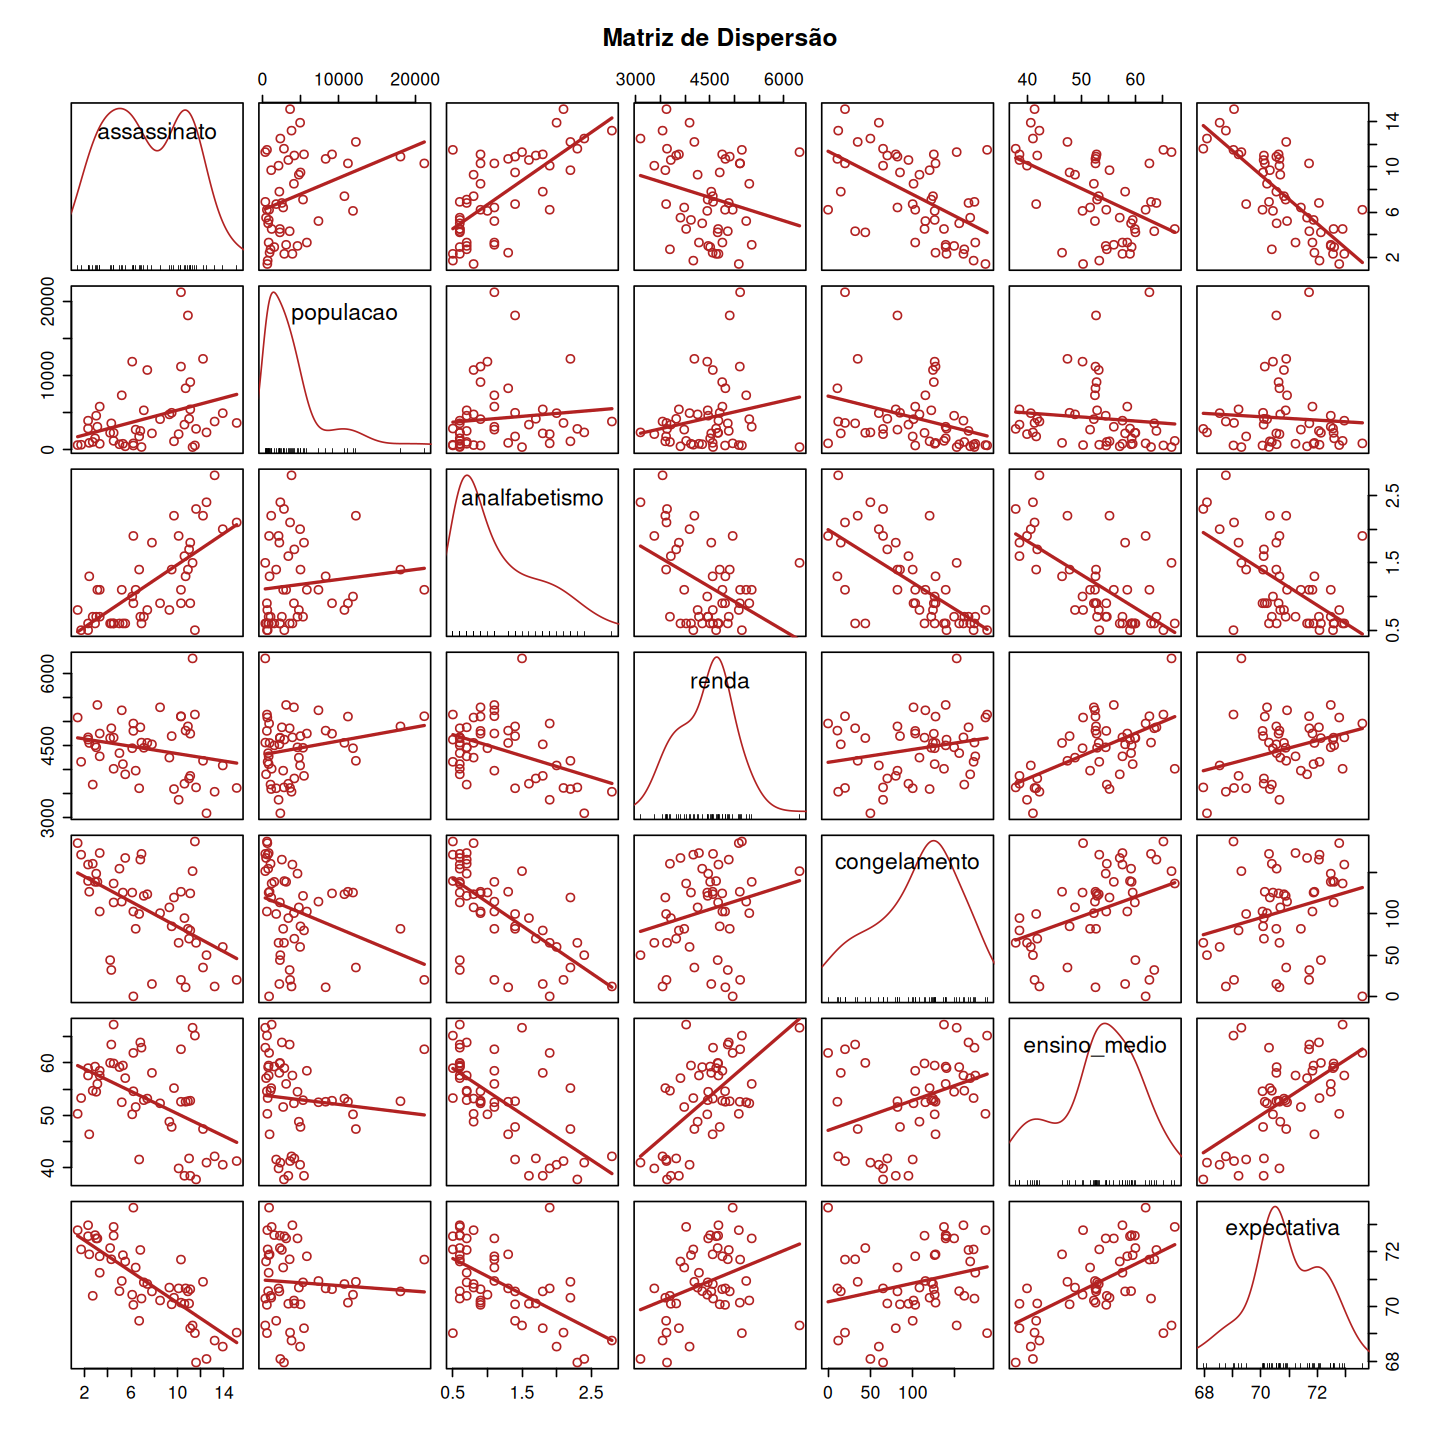

In [6]:
library(car)
grafdim(12,12)
varnum <- c("assassinato","populacao","analfabetismo","renda","congelamento","ensino_medio","expectativa")
scatterplotMatrix(st[,varnum], smooth=FALSE, col="firebrick", 
                  cex=1.2, cex.labels=1.7, cex.axis=1.3,
                  main="Matriz de Dispersão")

In [58]:
grafdim(11,3)

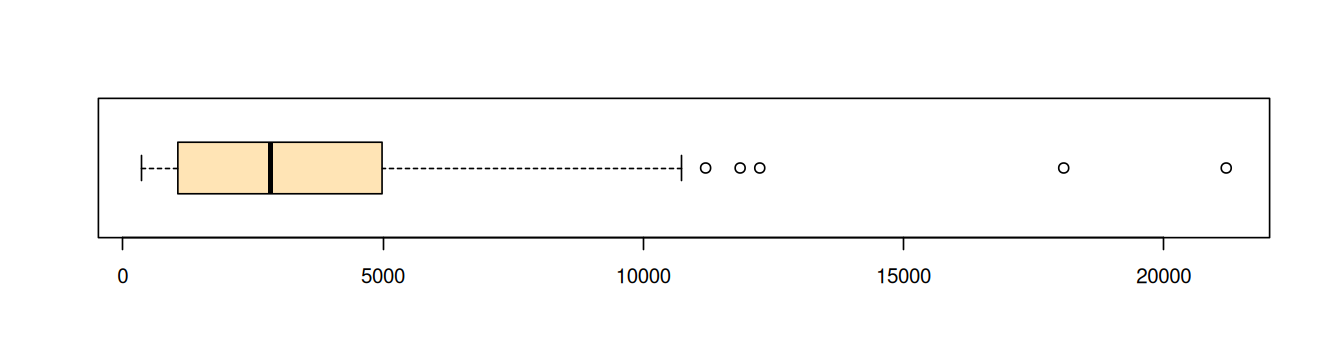

In [60]:
# se quiser examinar uma das variáveis em particular
boxplot(st$populacao, horizontal=TRUE, col="moccasin")

Utilizando um histrograma:

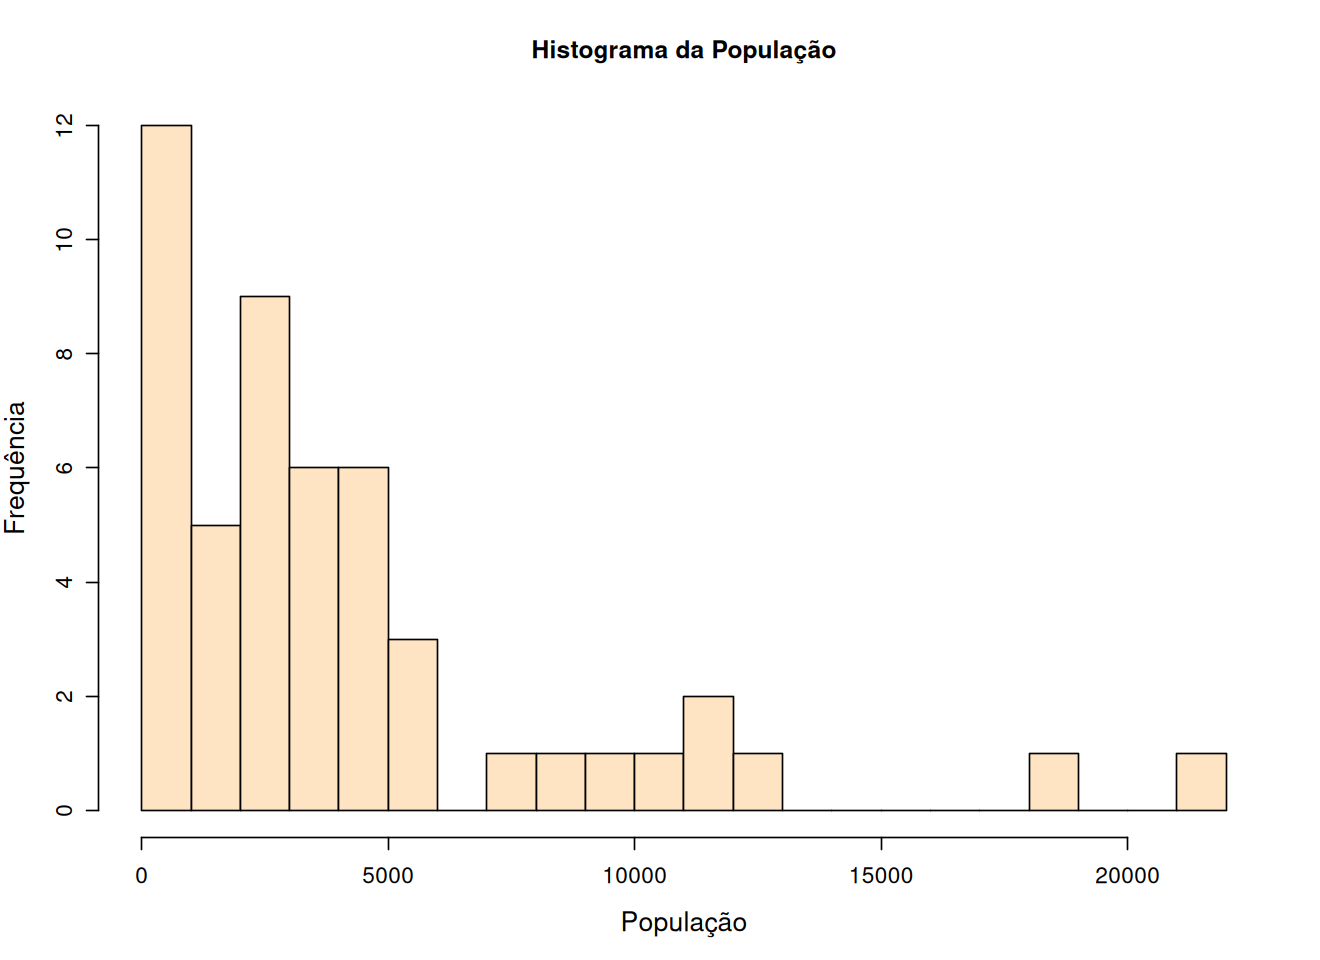

In [61]:
grafdim()
hist(st$populacao, main="Histograma da População", 
     xlab="População", ylab="Frequência", 
     cex.lab=1.3, cex.axis=1.1,
     col=c("bisque"), breaks=15)

Pode ser interessante comparar uma variável com outra. A seguir graficamos o _log_(`populacao`) com a proporção de `analfabetismo`. O tamanho dos pontos é proporcional à taxa de  `assassinato`:

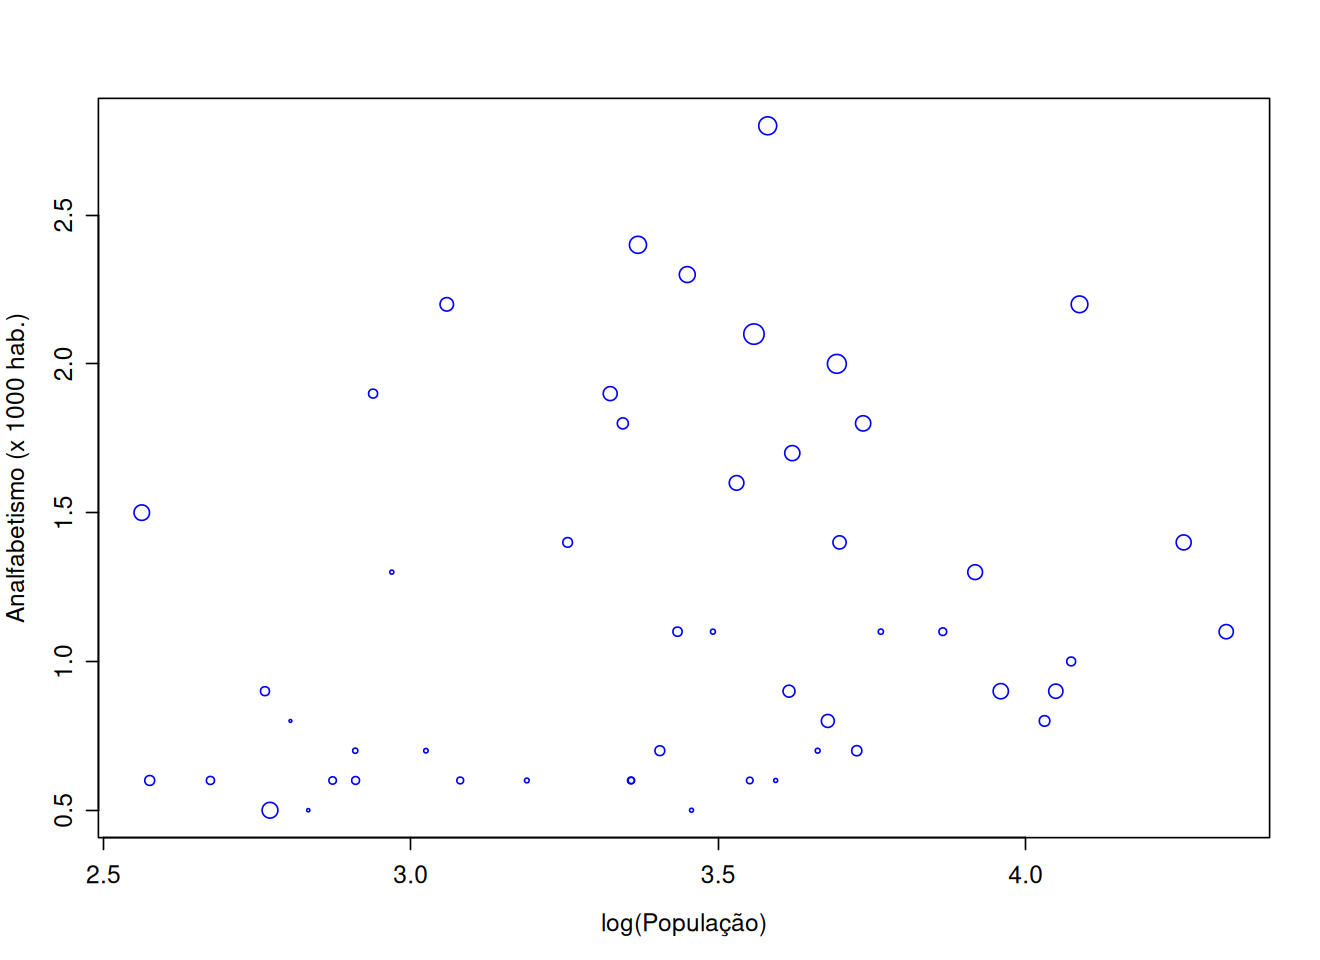

In [70]:
plot(log10(st$populacao), st$analfabetismo, col="blue", 
     cex=st$assassinato/7.0, cex.lab=1.2, cex.axis=1.2,
     xlab="log(População)", ylab="Analfabetismo (x 1000 hab.)")

In [16]:
# Correlação entre as variáveis -1 <= cor <= 1
round(cor(st[,varnum]),3)

,assassinato,populacao,analfabetismo,renda,congelamento,ensino_medio,expectativa
assassinato,1.000,0.344,0.703,-0.230,-0.539,-0.488,-0.781
populacao,0.344,1.000,0.108,0.208,-0.332,-0.098,-0.068
analfabetismo,0.703,0.108,1.000,-0.437,-0.672,-0.657,-0.588
renda,-0.230,0.208,-0.437,1.000,0.226,0.620,0.340
congelamento,-0.539,-0.332,-0.672,0.226,1.000,0.367,0.262
ensino_medio,-0.488,-0.098,-0.657,0.620,0.367,1.000,0.582
expectativa,-0.781,-0.068,-0.588,0.340,0.262,0.582,1.000


## Modelo Padrão-Base (_Baseline_)

A análise da melhoria do modelo se dá contrastando com um modelo inicial, considerado bom, para que as melhorias sejam significativas. Tal modelo é chamado de modelo-base ou _baseline_.

In [17]:
regbas <- lm(formula = assassinato ~ populacao + analfabetismo + 
                       renda + congelamento + ensino_medio + expectativa, 
             data=st)

In [18]:
summary(regbas)


Call:
lm(formula = assassinato ~ populacao + analfabetismo + renda + 
    congelamento + ensino_medio + expectativa, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.5237 -1.0835  0.0329  1.1502  3.0804 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)    1.257e+02  1.805e+01   6.965 1.45e-08 ***
populacao      1.922e-04  6.577e-05   2.923  0.00551 ** 
analfabetismo  1.913e+00  7.708e-01   2.481  0.01707 *  
renda          5.691e-05  5.651e-04   0.101  0.92025    
congelamento  -1.018e-02  7.310e-03  -1.392  0.17105    
ensino_medio   7.355e-02  5.174e-02   1.421  0.16240    
expectativa   -1.756e+00  2.522e-01  -6.963 1.45e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.775 on 43 degrees of freedom
Multiple R-squared:  0.797,	Adjusted R-squared:  0.7687 
F-statistic: 28.14 on 6 and 43 DF,  p-value: 2.217e-13


As variáveis `renda`, `congelamento` e `ensino_medio` não se mostraram significativamente (a $\alpha$=5%) diferentes de zero. Seria interessante avaliar o modelo sem elas.

In [19]:
regbas <- lm(formula = assassinato ~ populacao + analfabetismo + expectativa, 
             data=st)

In [20]:
summary(regbas)


Call:
lm(formula = assassinato ~ populacao + analfabetismo + expectativa, 
    data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.7412 -1.0472  0.1251  1.3323  3.4869 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)    1.131e+02  1.736e+01   6.514 4.89e-08 ***
populacao      2.220e-04  5.860e-05   3.788 0.000440 ***
analfabetismo  2.088e+00  5.297e-01   3.941 0.000274 ***
expectativa   -1.539e+00  2.397e-01  -6.423 6.71e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.821 on 46 degrees of freedom
Multiple R-squared:  0.7716,	Adjusted R-squared:  0.7567 
F-statistic: 51.81 on 3 and 46 DF,  p-value: 8.619e-15


Um indicador da qualidade da regressão é o erro absoluto médio (eam), que é a média da soma do absoluto das diferenças entre os valores observados e seus valores preditos, ou seja:
$$eam = \frac { \sum | y_i - \hat{y}_i |} {n} = \frac { \sum | observado_i - predito_i |} {n}$$

In [21]:
eam <- function(observado, predito) {
    return(sum(abs(observado - predito)) / length(observado))
}

Erro absoluto médio para a regressão básica:

In [22]:
sum(abs(regbas$residuals))/length(st$assassinato)
eam(st$assassinato, regbas$fitted.values)

[1] 1.45555

[1] 1.45555

O modelo para a taxa de assassinato então seria:

`Assassinato` $= 113,\!1 + 2,\!22·10^{-4}$ `populacao`+ $2,\!088$ `analfabetismo` $-1,\!539$ `expectativa`

À 5% de significância, ou seja com $\alpha$ = 0,05, apenas `Populacao` e `Analfabetismo` foram significativamente diferente de 0 em suas hipóteses nulas.

Observação: o nível de significância é **pré-fixado** em todo experimento. Normalmente 0,05.

In [23]:
grafdim()

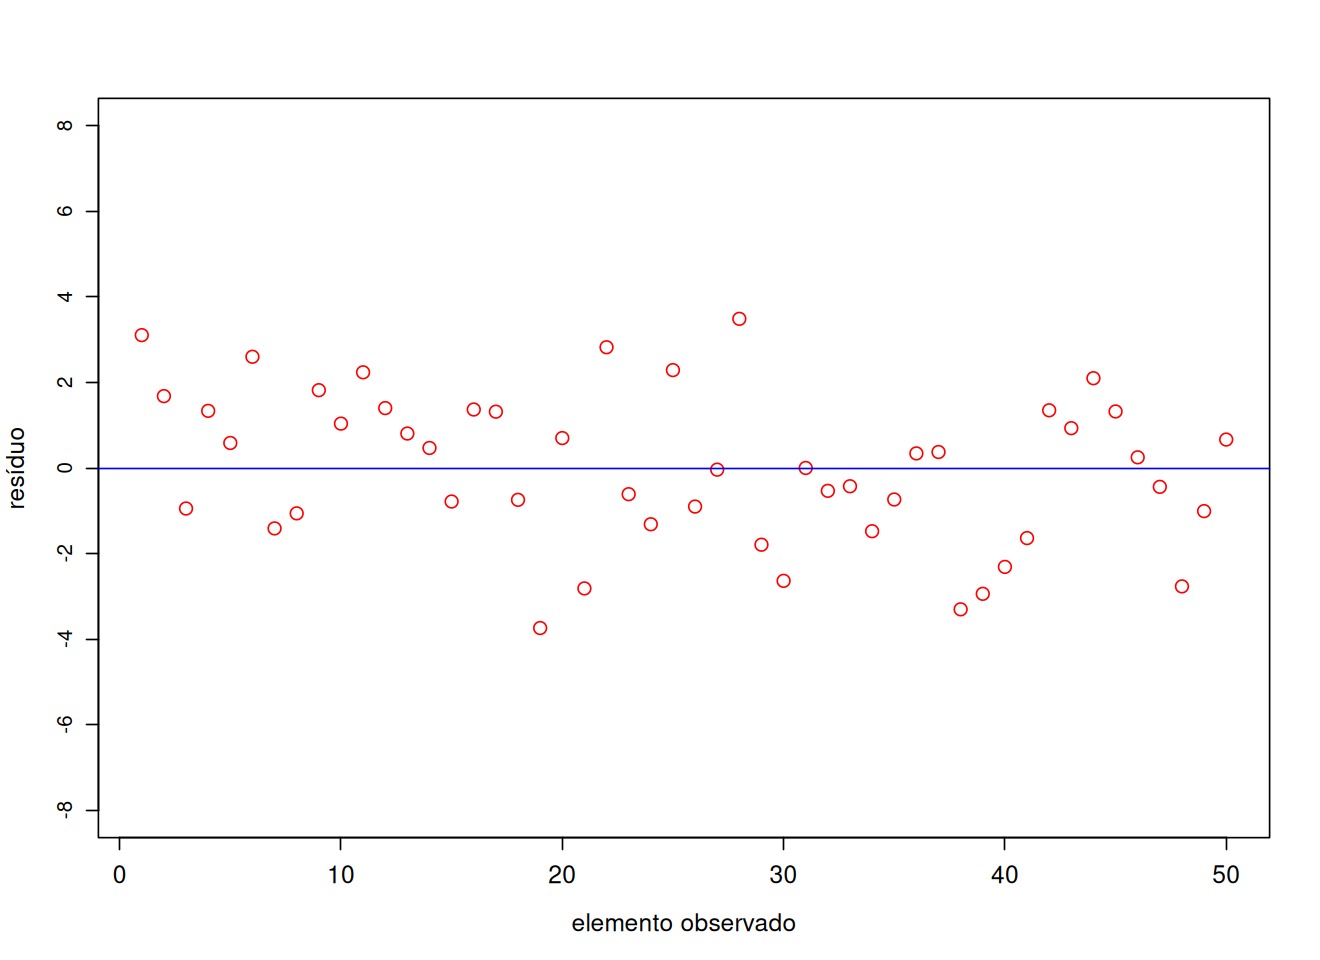

In [69]:
plot(regbas$residuals,
     xlab="elemento observado", ylab="resíduo", 
     cex=1.3, cex.lab=1.2, cex.axis=1.2, 
     ylim=c(-8,8), yaxt = "n", col="red")
axis(2, at=seq(-8,8,2))
abline(h=0.0, col="blue")

In [25]:
print(head(sort(regbas$residuals)))

        Maine  Pennsylvania  Rhode Island Massachusetts West Virginia 
    -3.741159     -3.303655     -2.941253     -2.815396     -2.767664 
   New Jersey 
    -2.637901 


In [26]:
print(tail(sort(regbas$residuals)))

  Hawaii Missouri Colorado Michigan  Alabama   Nevada 
2.236904 2.288546 2.600192 2.823166 3.106045 3.486866 


## Modelos Avançados

In [27]:
reg_nivel2 <- lm(formula= assassinato ~ 
                          populacao + analfabetismo + renda + 
                          congelamento + ensino_medio + expectativa +
                          populacao:analfabetismo + 
                          populacao:renda + 
                          populacao:congelamento +
                          populacao:ensino_medio + 
                          populacao:expectativa +
                          analfabetismo:renda + 
                          analfabetismo:congelamento + 
                          analfabetismo:ensino_medio +
                          analfabetismo:expectativa +
                          renda:congelamento + 
                          renda:ensino_medio + 
                          renda:expectativa +
                          congelamento:ensino_medio +
                          congelamento:expectativa,
                data=st)

In [66]:
summary(reg_nivel2)


Call:
lm(formula = assassinato ~ populacao + analfabetismo + renda + 
    congelamento + ensino_medio + expectativa + populacao:analfabetismo + 
    populacao:renda + populacao:congelamento + populacao:ensino_medio + 
    populacao:expectativa + analfabetismo:renda + analfabetismo:congelamento + 
    analfabetismo:ensino_medio + analfabetismo:expectativa + 
    renda:congelamento + renda:ensino_medio + renda:expectativa + 
    congelamento:ensino_medio + congelamento:expectativa, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.8257 -0.6045  0.1748  0.5865  3.3135 

Coefficients:
                             Estimate Std. Error t value Pr(>|t|)  
(Intercept)                -1.035e+02  2.057e+02  -0.503   0.6186  
populacao                   2.002e-02  1.208e-02   1.657   0.1083  
analfabetismo              -1.620e+01  5.037e+01  -0.322   0.7500  
renda                       2.885e-02  3.325e-02   0.868   0.3926  
congelamento                2.051e-01  6.266e-01   0.3

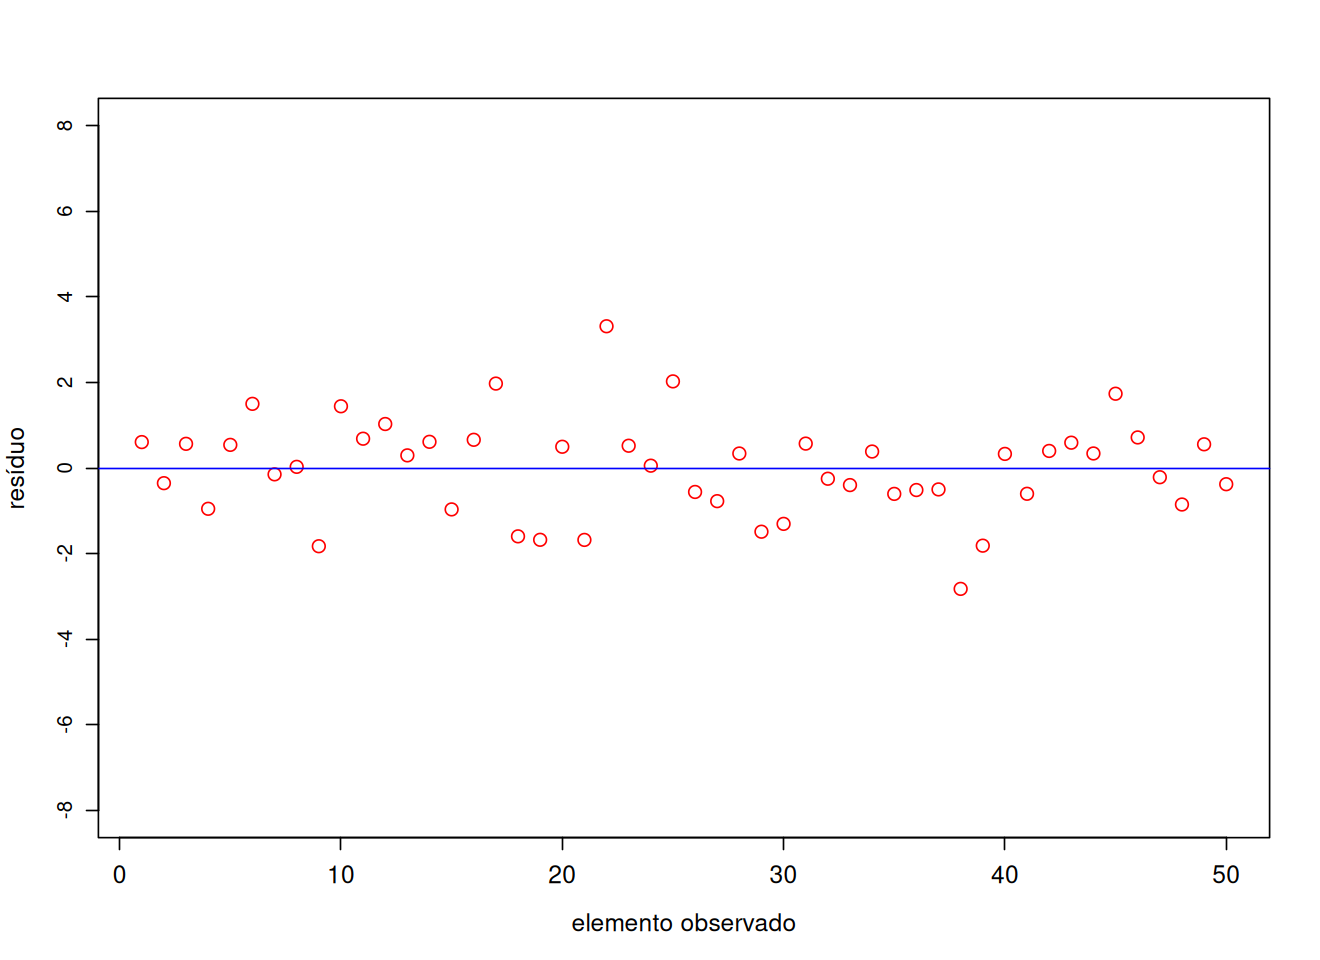

In [68]:
plot(reg_nivel2$residuals,
     xlab="elemento observado", ylab="resíduo", 
     cex=1.3, cex.lab=1.2, cex.axis=1.2,
     ylim=c(-8,8), yaxt = "n", col="red")
axis(2, at=seq(-8,8,2))
abline(h=0.0, col="blue")

In [30]:
eam(st$assassinato,reg_nivel2$fitted.values)

[1] 0.8921286

In [31]:
reg_nivel3 <- lm(formula = assassinato ~ 
                          (populacao + analfabetismo + renda + 
                           congelamento + ensino_medio + expectativa)^3,
              data=st)

In [32]:
summary(reg_nivel3)


Call:
lm(formula = assassinato ~ (populacao + analfabetismo + renda + 
    congelamento + ensino_medio + expectativa)^3, data = st)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.66577 -0.35397 -0.00463  0.20403  2.94508 

Coefficients:
                                          Estimate Std. Error t value Pr(>|t|)
(Intercept)                             -1.037e+03  1.186e+04  -0.087    0.932
populacao                               -2.988e-01  6.794e-01  -0.440    0.672
analfabetismo                           -1.401e+03  2.993e+03  -0.468    0.652
renda                                    1.794e+00  2.308e+00   0.777    0.459
congelamento                            -4.668e+01  4.027e+01  -1.159    0.280
ensino_medio                             7.649e+01  1.026e+02   0.746    0.477
expectativa                             -2.065e+00  1.902e+02  -0.011    0.992
populacao:analfabetismo                 -5.657e-03  1.629e-01  -0.035    0.973
populacao:renda                      

O modelo, com interações até o 3º nível, não explica satisfatóriamente o comportamento de `Assassinato` em função de suas variáveis.  
Poderíamos melhorar o modelo de 2º nível mantendo as interações consideradas significativas e as variáveis de 1º nível:

In [33]:
reg_nivel2_simp <- lm(formula= assassinato ~ 
                          populacao + analfabetismo + renda + 
                          congelamento + ensino_medio + expectativa +
                          populacao:congelamento +
                          congelamento:ensino_medio,
                      data=st)

In [34]:
summary(reg_nivel2_simp)


Call:
lm(formula = assassinato ~ populacao + analfabetismo + renda + 
    congelamento + ensino_medio + expectativa + populacao:congelamento + 
    congelamento:ensino_medio, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.0390 -0.9854 -0.0126  0.9474  3.4642 

Coefficients:
                            Estimate Std. Error t value Pr(>|t|)    
(Intercept)                1.121e+02  1.681e+01   6.667 4.87e-08 ***
populacao                  2.246e-04  9.843e-05   2.282  0.02774 *  
analfabetismo              1.164e+00  7.322e-01   1.590  0.11957    
renda                      4.827e-04  5.303e-04   0.910  0.36804    
congelamento              -1.717e-01  4.891e-02  -3.510  0.00110 ** 
ensino_medio              -2.496e-01  1.062e-01  -2.351  0.02363 *  
expectativa               -1.326e+00  2.611e-01  -5.078 8.72e-06 ***
populacao:congelamento    -1.133e-07  1.089e-06  -0.104  0.91768    
congelamento:ensino_medio  2.812e-03  8.344e-04   3.370  0.00165 ** 
---
Signif. co

Aparentemente há espaço pra melhoria, considerando apenas as variáveis significativas de 1º nível:

In [35]:
reg_nivel2_simp2 <- lm(formula= assassinato ~ 
                          populacao +  
                          congelamento + ensino_medio + expectativa +
                          congelamento:ensino_medio,
                      data=st)

In [36]:
summary(reg_nivel2_simp2)


Call:
lm(formula = assassinato ~ populacao + congelamento + ensino_medio + 
    expectativa + congelamento:ensino_medio, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.8632 -1.1720 -0.1792  1.0812  3.3888 

Coefficients:
                            Estimate Std. Error t value Pr(>|t|)    
(Intercept)                1.258e+02  1.522e+01   8.262 1.70e-10 ***
populacao                  2.220e-04  5.682e-05   3.907 0.000318 ***
congelamento              -1.912e-01  4.362e-02  -4.383 7.18e-05 ***
ensino_medio              -2.760e-01  8.653e-02  -3.190 0.002624 ** 
expectativa               -1.439e+00  2.554e-01  -5.634 1.16e-06 ***
congelamento:ensino_medio  3.037e-03  7.769e-04   3.909 0.000316 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.617 on 44 degrees of freedom
Multiple R-squared:  0.8277,	Adjusted R-squared:  0.8082 
F-statistic: 42.28 on 5 and 44 DF,  p-value: 1.011e-15


## Modelo Escolhido

Apesar de não apresentar a maior explicação da variabilidade ($R^2$), o modelo mais razoável por ser simples (sem interações complexas de 2º ou 3º nível) com um bom valor de $R^2 = 0,\!8082$ seria `reg_nivel2_simp2`:

In [92]:
summary(reg_nivel2_simp2)


Call:
lm(formula = assassinato ~ populacao + congelamento + ensino_medio + 
    expectativa + congelamento:ensino_medio, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.8632 -1.1720 -0.1792  1.0812  3.3888 

Coefficients:
                            Estimate Std. Error t value Pr(>|t|)    
(Intercept)                1.258e+02  1.522e+01   8.262 1.70e-10 ***
populacao                  2.220e-04  5.682e-05   3.907 0.000318 ***
congelamento              -1.912e-01  4.362e-02  -4.383 7.18e-05 ***
ensino_medio              -2.760e-01  8.653e-02  -3.190 0.002624 ** 
expectativa               -1.439e+00  2.554e-01  -5.634 1.16e-06 ***
congelamento:ensino_medio  3.037e-03  7.769e-04   3.909 0.000316 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.617 on 44 degrees of freedom
Multiple R-squared:  0.8277,	Adjusted R-squared:  0.8082 
F-statistic: 42.28 on 5 and 44 DF,  p-value: 1.011e-15


In [93]:
print(reg_nivel2_simp2$coefficients)

              (Intercept)                 populacao              congelamento 
             1.257591e+02              2.219971e-04             -1.911918e-01 
             ensino_medio               expectativa congelamento:ensino_medio 
            -2.760216e-01             -1.439071e+00              3.036967e-03 


O modelo final:  

$
\begin{equation}
\begin{aligned}
\textsf{assassinato} = & {}125,\!759 + 2,\!21997\cdot 10^{-4}\cdot \textsf{populacao} -0,\!191191\cdot \textsf{congelamento} - 0,\!276022\cdot \textsf{ensino\_medio} + \\
&-1,\!43907\cdot \textsf{expectativa} + 0,\!00303697\cdot \textsf{congelamento} \cdot \textsf{ensino\_medio}
\end{aligned}
\end{equation}
$

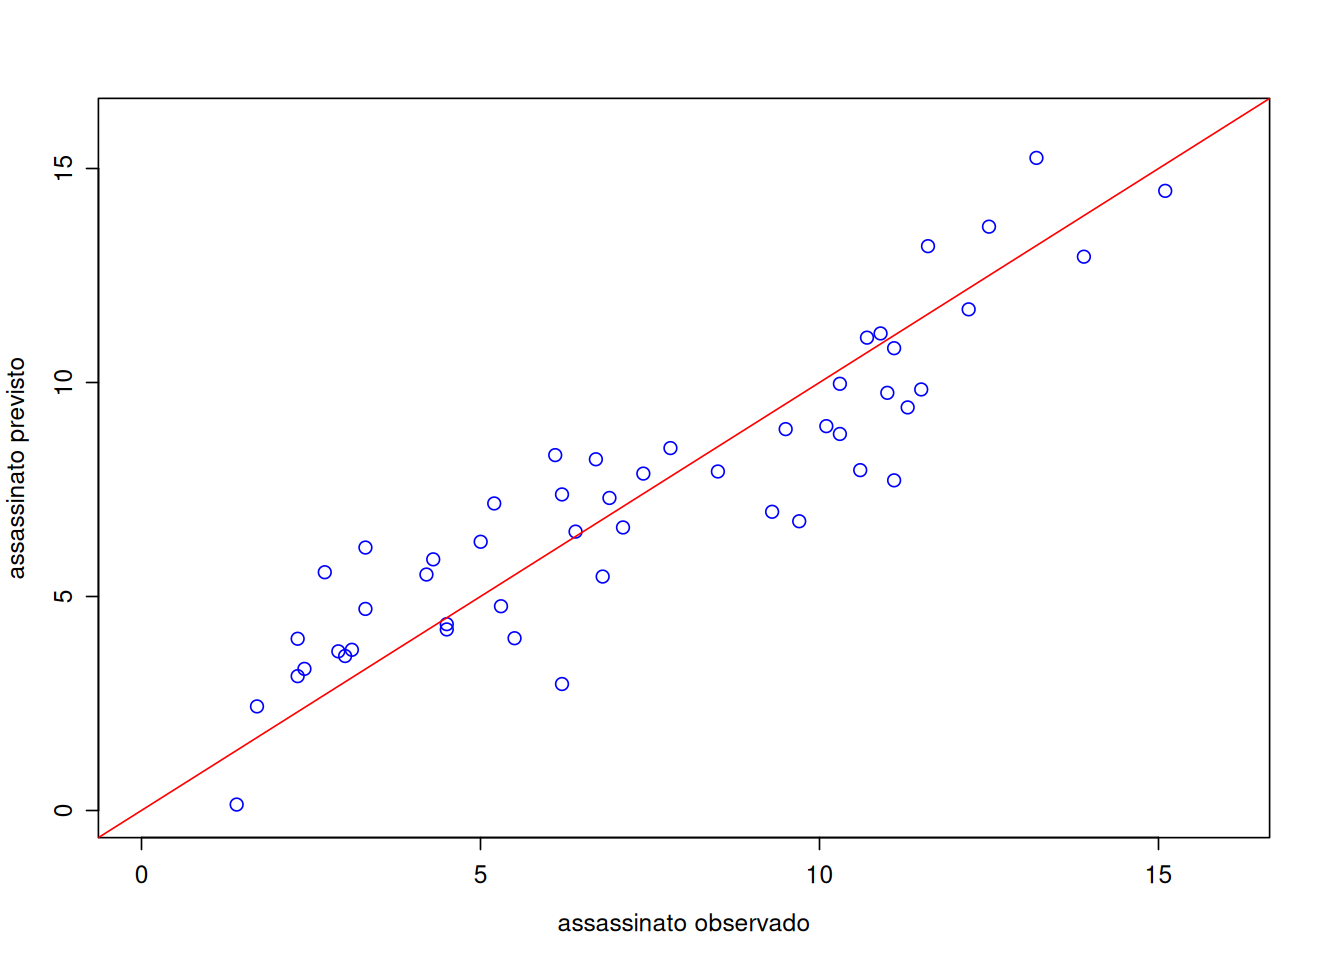

In [94]:
plot(st$assassinato, reg_nivel2_simp2$fitted.values, col=c("blue"),
     xlim=c(0,16), ylim=c(0, 16),
     xlab="assassinato observado", ylab="assassinato previsto",
     cex.lab=1.2, cex.axis=1.2, cex=1.3)
abline(a=0, b=1, col="red")

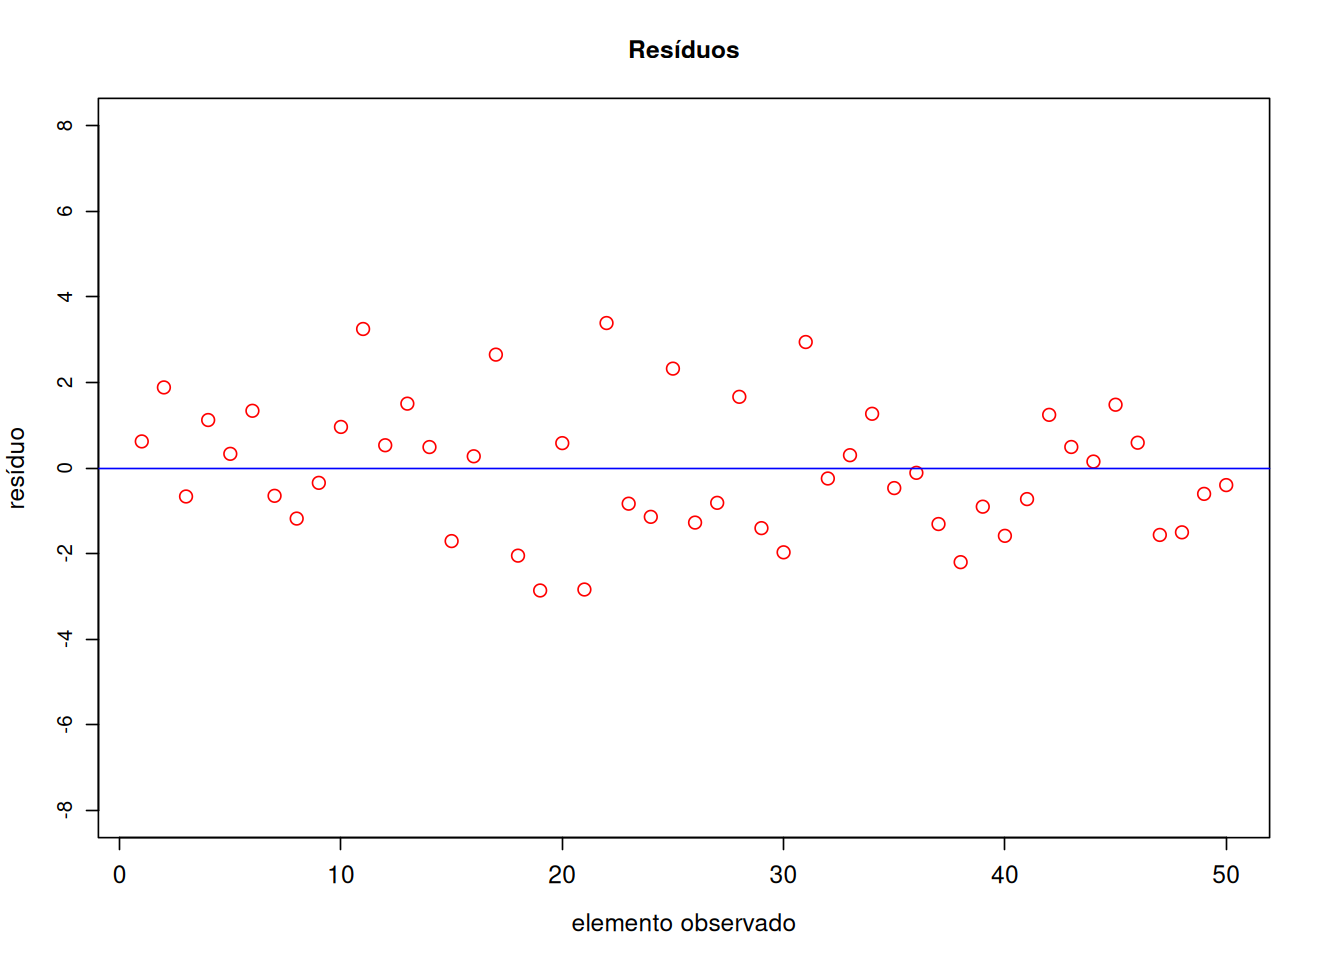

In [95]:
plot(reg_nivel2_simp2$residuals, col="red", 
     cex.lab=1.2, cex.axis=1.2, cex=1.3,
     xlab="elemento observado", ylab="resíduo", main="Resíduos",
     ylim=c(-8,8), yaxt="n")
axis(2,at = seq(-8,8,2))
abline(h=0.0, col="blue")

In [96]:
aval <- cbind(data.frame("residuo"=reg_nivel2_simp2$residuals,"predito"=reg_nivel2_simp2$fitted.values), 
              st[,c("assassinato","populacao","congelamento","ensino_medio","expectativa")])
aval[abs(aval$residuo) > 2.5, ]

,residuo,predito,assassinato,populacao,congelamento,ensino_medio,expectativa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Hawaii,3.249554,2.950446,6.2,868,0,61.9,73.60
Kentucky,2.650205,7.949795,10.6,3387,95,38.5,70.10
Maine,-2.863175,5.563175,2.7,1058,161,54.7,70.39
Massachusetts,-2.840562,6.140562,3.3,5814,103,58.5,71.83
Michigan,3.388788,7.711212,11.1,9111,125,52.8,70.63
New Mexico,2.944933,6.755067,9.7,1144,120,55.2,70.32


Vamos utilizar o modelo para estimar um valor de taxa de assassinato para um caso particular. Vamos utilizar como base os dados do estado de "New York":

In [98]:
caso <- st['New York',]
vars <- c("assassinato","populacao","analfabetismo","renda",
          "congelamento","ensino_medio","expectativa")
caso[,vars]

,assassinato,populacao,analfabetismo,renda,congelamento,ensino_medio,expectativa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
New York,10.9,18076,1.4,4903,82,52.7,70.55


Ajustando alguns valores das variáveis preditoras (_features_):

In [99]:
rownames(caso) <- "predição"
caso$analfabetismo <-   2.8         # dobrar a taxa de analfabetismo
caso$ensino_medio  <-  26.35        # diminuir o ensino médio pela metade
caso$expectativa   <-  69.55        # diminuir a expectativa de vida em um ano

Utilizando o modelo para predizer qual seria a taxa de assassinato para esse caso:

In [100]:
caso$assassinato   <- predict(reg_nivel2_simp2, caso)
caso[,vars]

,assassinato,populacao,analfabetismo,renda,congelamento,ensino_medio,expectativa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
predição,13.29562,18076,2.8,4903,82,26.35,69.55


O valor predito, para essa situação hipotética, seria 13,3 assassinatos para cada 100000 habitantes, 2,4 a mais que o original (New York), se o analfabetismo dobrar (2,8), a taxa de concluintes do ensino médio for a metade (26,35) e a expectativa de vida for de um ano a menos (69,55).